In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
train_df = pd.read_csv('train.csv')
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
test_df = pd.read_csv('test.csv')
test_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [4]:
test_df.shape

(418, 11)

In [5]:
train_df.shape

(891, 12)

## Join the both dataset 

In [6]:
df = pd.concat([train_df.drop(columns=['Survived']), test_df]).sample(1309)

In [26]:
df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
29,30,3,"Todoroff, Mr. Lalio",male,NaN,0,0,349216,7.8958,NaN,S
445,446,1,"Dodge, Master. Washington",male,4.0,0,2,33638,81.8583,A34,S
239,240,2,"Hunt, Mr. George Henry",male,33.0,0,0,SCO/W 1585,12.2750,NaN,S
311,312,1,"Ryerson, Miss. Emily Borie",female,18.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
643,644,3,"Foo, Mr. Choong",male,NaN,0,0,1601,56.4958,NaN,S


<Axes: ylabel='Density'>

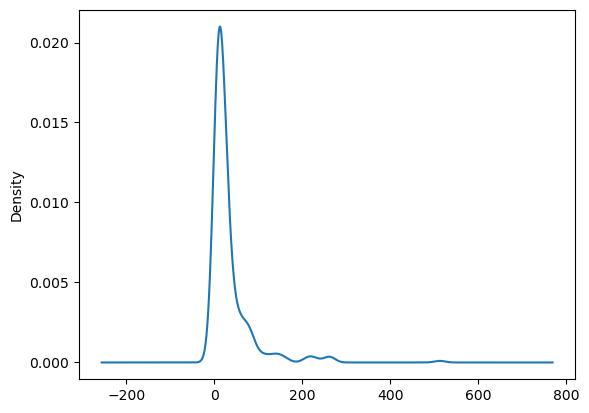

In [7]:
df['Fare'].plot(kind='kde')

## Create sample size 50 and num_samples = 100

In [9]:
samples = []
for i in range(100):
    samples.append(df['Fare'].dropna().sample(50).values.tolist())

In [10]:
len(samples)

100

In [11]:
np.array(samples)

array([[  8.05  ,  27.7208,  26.25  , ...,  51.8625,  26.    ,  29.125 ],
       [ 13.    ,   7.125 ,  10.5   , ...,   7.7958,  10.5   ,  14.5   ],
       [  8.05  ,  14.5   , 134.5   , ...,  29.    ,   0.    , 262.375 ],
       ...,
       [ 52.5542, 135.6333,   8.1583, ...,   8.05  , 113.275 ,  26.55  ],
       [ 65.    ,   7.8542, 120.    , ...,  52.    ,  55.4417,  35.5   ],
       [  8.3625,  79.2   ,  13.    , ...,   7.2292,  20.2125,   7.775 ]])

In [16]:
samples = np.array(samples)

In [17]:
samples

array([[  8.05  ,  27.7208,  26.25  , ...,  51.8625,  26.    ,  29.125 ],
       [ 13.    ,   7.125 ,  10.5   , ...,   7.7958,  10.5   ,  14.5   ],
       [  8.05  ,  14.5   , 134.5   , ...,  29.    ,   0.    , 262.375 ],
       ...,
       [ 52.5542, 135.6333,   8.1583, ...,   8.05  , 113.275 ,  26.55  ],
       [ 65.    ,   7.8542, 120.    , ...,  52.    ,  55.4417,  35.5   ],
       [  8.3625,  79.2   ,  13.    , ...,   7.2292,  20.2125,   7.775 ]])

In [18]:
sampling_means = samples.mean(axis=1)

<Axes: ylabel='Density'>

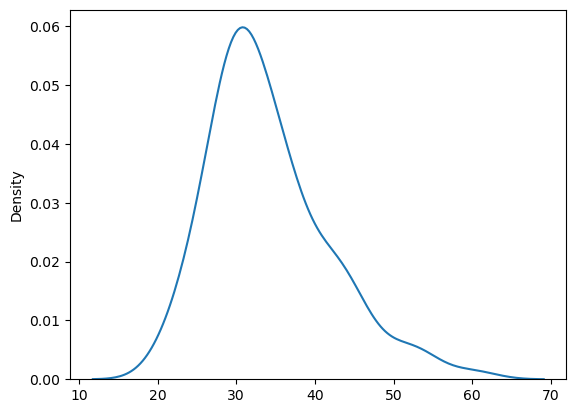

In [19]:
sns.kdeplot(sampling_means)

In [21]:
sampling_means.mean()

np.float64(34.06944944)

### Empirical Rule

In [22]:
lower_limit = sampling_means.mean() - 2*sampling_means.std() / np.sqrt(50)

upper_limit = sampling_means.mean() + 2*sampling_means.std() / np.sqrt(50)

In [23]:
print('The Range is', lower_limit, '-', upper_limit)

The Range is 31.94766444137959 - 36.191234438620405


In [24]:
df['Fare'].mean()

np.float64(33.29547928134557)

In [25]:
df['Fare'].dropna().mean()

np.float64(33.29547928134557)

In [27]:
### PassengerId

In [28]:
df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
29,30,3,"Todoroff, Mr. Lalio",male,NaN,0,0,349216,7.8958,NaN,S
445,446,1,"Dodge, Master. Washington",male,4.0,0,2,33638,81.8583,A34,S
239,240,2,"Hunt, Mr. George Henry",male,33.0,0,0,SCO/W 1585,12.2750,NaN,S
311,312,1,"Ryerson, Miss. Emily Borie",female,18.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
643,644,3,"Foo, Mr. Choong",male,NaN,0,0,1601,56.4958,NaN,S


<Axes: ylabel='Density'>

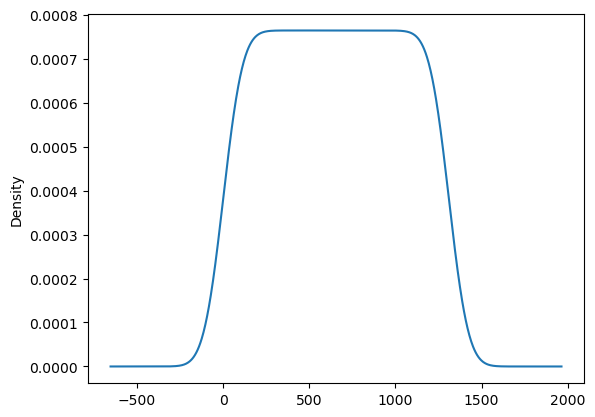

In [29]:
df['PassengerId'].plot(kind='kde')

In [30]:
## sample size =50 AND 100 times

In [31]:
samples = []
for i in range(100):
    samples.append(df['PassengerId'].dropna().sample(50).values.tolist())

In [32]:
len(samples)

100

In [33]:
samples = np.array(samples)

In [34]:
sampling_means = samples.mean(axis=1)

<Axes: ylabel='Density'>

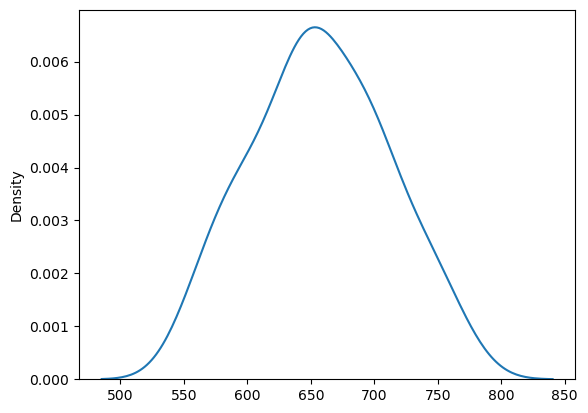

In [35]:
sns.kdeplot(sampling_means)

In [36]:
lower_limit = sampling_means.mean() - 2*sampling_means.std() / np.sqrt(50)

upper_limit = sampling_means.mean() + 2*sampling_means.std() / np.sqrt(50)

In [37]:
print('The Range is', lower_limit, '-', upper_limit)

The Range is 642.0047112355857 - 672.3508887644147


In [38]:
df['PassengerId'].mean()

np.float64(655.0)

In [39]:
df['PassengerId'].dropna().mean()

np.float64(655.0)